# Exercise 2 — Double DQN and Dueling DQN — ALE/Pong-v5

Two classic improvements, evaluated one at a time: the Double DQN target removes the max-operator bias, the dueling head separates the value of the state from the advantage of each action. Four agents share everything except the target and the head.

**Protocol.** Every comparison uses the same hyperparameters and the same seeds (0, 1, 2);
only one setting changes at a time. For each run we report the *training score* (mean return
of the last 20 games) and the
*greedy score* (ε = 0, 20 fresh evaluation episodes with seeds 100 000 + i, never used during
training). A difference between two variants is only meaningful if it is larger than the
min–max band across the three seeds.

## 0. Environment, preprocessing and hyperparameters

| Element | ALE/Pong-v5 |
|---|---|
| Raw observation | RGB frame 210 x 160 x 3 at 60 fps |
| State | stack of the last 4 preprocessed frames, `uint8`, shape `(4, 84, 84)` |
| Actions | 6 — NOOP, FIRE, RIGHT, LEFT, RIGHTFIRE, LEFTFIRE |
| Reward | +1 when the agent scores, -1 when the opponent scores |
| Terminated | one player reaches 21 points |
| Solved (our convention) | average return >= 18 over the last 20 games |

Preprocessing (Mnih et al., 2015), built from the Gymnasium wrappers:
frame skip 4 with max-pooling of the last two frames, grayscale 84 x 84, up to 30 random no-ops at
reset, stack of the last 4 frames, no sticky actions. Frames stay `uint8` in the replay memory
(56 KB per transition instead of 226 KB) and are divided by 255 inside the network.

In [1]:
# @title 1. Setup — run this cell first
import os, sys, json, shutil, subprocess

REPO_URL = "https://github.com/AmirBnsL/rl-homework-dqn.git"
ENV_NAME = 'pong'

# In Colab, fetch the repository (it holds `runs/`); in the delivered archive, nothing is cloned.
root = os.path.abspath(".")
while not os.path.isdir(os.path.join(root, "runs")) and os.path.dirname(root) != root:
    root = os.path.dirname(root)
if not os.path.isdir(os.path.join(root, "runs")):
    if not os.path.isdir("rl-homework-dqn"):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL], check=True)
    root = os.path.abspath("rl-homework-dqn")
os.chdir(root)
os.makedirs("runs", exist_ok=True)
os.makedirs("deliverables", exist_ok=True)

import numpy as np
import pandas as pd
import torch
import gymnasium
import matplotlib.pyplot as plt
from IPython.display import display

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"working directory : {os.getcwd()}")
print(f"python {sys.version.split()[0]} | torch {torch.__version__} | "
      f"gymnasium {gymnasium.__version__}")
print(f"device            : {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

working directory : /home/amirbnsl/Documents/TPs5CS/RL/rl-homework
python 3.12.13 | torch 2.14.1+cpu | gymnasium 1.4.0
device            : cpu


In [2]:
# @title 3. Library (inlined)
# ============================================================================
# Library — identical to dqnlib/ in the repository, inlined so that this
# notebook is self-contained. Order matters: helpers, networks, replay, agent,
# environments, training, experiments, plots.
# ============================================================================

# ----------------------------------------------------------------------------
# dqnlib/utils.py
# ----------------------------------------------------------------------------
"""Small helpers shared by every other module (seeding, schedules, atomic saves)."""

import json
import os
import random
import tempfile

import numpy as np
import torch


def set_seed(seed: int) -> None:
    """Seed every random number generator we use (Python, NumPy, PyTorch, CUDA)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def get_device(prefer_cuda: bool = True) -> torch.device:
    if prefer_cuda and torch.cuda.is_available():
        return torch.device("cuda:0")
    return torch.device("cpu")


def epsilon_at(step: int, eps_start: float = 1.0, eps_end: float = 0.05,
               eps_decay_steps: int = 10_000) -> float:
    """Linear epsilon schedule: eps_start at step 0, eps_end after the decay, then constant."""
    fraction = min(1.0, step / eps_decay_steps)
    return float(eps_start + fraction * (eps_end - eps_start))


def moving_average(values, window: int) -> np.ndarray:
    """Centred-free trailing moving average, same convention as pandas' rolling(min_periods=1)."""
    values = np.asarray(values, dtype=np.float64)
    if len(values) == 0:
        return values
    out = np.empty_like(values)
    cumsum = np.cumsum(np.insert(values, 0, 0.0))
    for i in range(len(values)):
        lo = max(0, i + 1 - window)
        out[i] = (cumsum[i + 1] - cumsum[lo]) / (i + 1 - lo)
    return out


def atomic_savez(path: str, **arrays) -> None:
    """Write an .npz without leaving a half-written file behind if the run is killed."""
    path = str(path)
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    tmp = path + ".tmp.npz"
    np.savez_compressed(tmp, **arrays)
    os.replace(tmp, path)


def atomic_save_json(path: str, payload: dict) -> None:
    path = str(path)
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    tmp = path + ".tmp"
    with open(tmp, "w") as fh:
        json.dump(payload, fh, indent=2, sort_keys=True)
    os.replace(tmp, path)


def atomic_save_torch(path: str, state_dict: dict) -> None:
    path = str(path)
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    fd, tmp = tempfile.mkstemp(dir=os.path.dirname(path) or ".", suffix=".pth")
    os.close(fd)
    torch.save(state_dict, tmp)
    os.replace(tmp, path)


def format_seconds(seconds: float) -> str:
    seconds = int(round(seconds))
    hours, rest = divmod(seconds, 3600)
    minutes, secs = divmod(rest, 60)
    if hours:
        return f"{hours}h{minutes:02d}m"
    if minutes:
        return f"{minutes}m{secs:02d}s"
    return f"{secs}s"

# ----------------------------------------------------------------------------
# dqnlib/networks.py
# ----------------------------------------------------------------------------
"""Q-networks: the MLP of CartPole/LunarLander, the Nature CNN of Pong, and their dueling heads.

Every network takes the state as input and returns **one Q-value per action**, so the greedy
action is simply the argmax of a single forward pass.

Dueling heads (Wang et al., 2016) split the output into a state value V(s) and an advantage
A(s, a), recombined as

    Q(s, a) = V(s) + A(s, a) - (1 / |A|) sum_{a'} A(s, a')

which removes the unidentifiability of the (V, A) decomposition.
"""

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

CNN_FEATURES = 64 * 7 * 7  # 3 136: size of the Nature encoder output for an 84x84 input


def _prep_pixels(x: torch.Tensor) -> torch.Tensor:
    """Replay memory stores uint8 frames: convert and scale to [0, 1] inside the network."""
    if x.dtype == torch.uint8:
        return x.float().div_(255.0)
    return x.div(255.0)


class QNetwork(nn.Module):
    """MLP state_dim -> hidden_dim -> hidden_dim -> action_dim, ReLU, linear output."""

    def __init__(self, state_dim: int, action_dim: int, hidden_dim: int = 64):
        super().__init__()
        self.fc1 = nn.Linear(state_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.out = nn.Linear(hidden_dim, action_dim)

    def forward(self, state: torch.Tensor) -> torch.Tensor:
        x = F.relu(self.fc1(state))
        x = F.relu(self.fc2(x))
        return self.out(x)


class NatureEncoder(nn.Module):
    """The three convolutions of Mnih et al. (2015): (C, 84, 84) -> 3 136 features."""

    def __init__(self, in_channels: int = 4):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, 32, kernel_size=8, stride=4)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=4, stride=2)
        self.conv3 = nn.Conv2d(64, 64, kernel_size=3, stride=1)

    def forward(self, state: torch.Tensor) -> torch.Tensor:
        x = _prep_pixels(state)
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.conv3(x))
        return torch.flatten(x, 1)


class NatureCNN(nn.Module):
    """Nature CNN: encoder -> FC 512 -> linear 6 Q-values (1 687 206 parameters)."""

    def __init__(self, action_dim: int, in_channels: int = 4):
        super().__init__()
        self.encoder = NatureEncoder(in_channels)
        self.fc = nn.Linear(CNN_FEATURES, 512)
        self.out = nn.Linear(512, action_dim)

    def forward(self, state: torch.Tensor) -> torch.Tensor:
        x = F.relu(self.fc(self.encoder(state)))
        return self.out(x)


class DuelingQNetwork(nn.Module):
    """MLP with the dueling head: shared body, then a value stream and an advantage stream."""

    def __init__(self, state_dim: int, action_dim: int, hidden_dim: int = 64):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(state_dim, hidden_dim), nn.ReLU())
        self.value = nn.Sequential(nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
                                   nn.Linear(hidden_dim, 1))
        self.advantage = nn.Sequential(nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
                                       nn.Linear(hidden_dim, action_dim))

    def forward(self, state: torch.Tensor) -> torch.Tensor:
        h = self.body(state)
        v = self.value(h)
        a = self.advantage(h)
        return v + a - a.mean(dim=1, keepdim=True)


class DuelingNatureCNN(nn.Module):
    """Nature CNN with the dueling head: 3 136 -> 512 streams for V and A."""

    def __init__(self, action_dim: int, in_channels: int = 4):
        super().__init__()
        self.encoder = NatureEncoder(in_channels)
        self.value = nn.Sequential(nn.Linear(CNN_FEATURES, 512), nn.ReLU(), nn.Linear(512, 1))
        self.advantage = nn.Sequential(nn.Linear(CNN_FEATURES, 512), nn.ReLU(),
                                       nn.Linear(512, action_dim))

    def forward(self, state: torch.Tensor) -> torch.Tensor:
        h = self.encoder(state)
        v = self.value(h)
        a = self.advantage(h)
        return v + a - a.mean(dim=1, keepdim=True)


def make_q_network(kind: str, state_shape, action_dim: int, hidden_dim: int = 64,
                   dueling: bool = False) -> nn.Module:
    """Build the network named by the environment spec ("mlp" or "cnn"), plain or dueling."""
    if kind == "mlp":
        state_dim = int(np.prod(state_shape))
        cls = DuelingQNetwork if dueling else QNetwork
        return cls(state_dim, action_dim, hidden_dim)
    if kind == "cnn":
        channels = int(state_shape[0]) if len(state_shape) == 3 else 4
        cls = DuelingNatureCNN if dueling else NatureCNN
        return cls(action_dim, in_channels=channels)
    raise ValueError(f"unknown network kind: {kind!r}")

# ----------------------------------------------------------------------------
# dqnlib/replay.py
# ----------------------------------------------------------------------------
"""Experience replay.

Two storage modes:

* **uniform replay** (the reference DQN): a FIFO ring buffer of `capacity` transitions from which
  minibatches are drawn uniformly at random, which decorrelates the samples of a gradient step;
* **no replay**: only the `batch_size` most recent transitions are kept and `sample()` returns them
  *in chronological order*. The agent then performs SGD on a single consecutive trajectory.

For Atari the states are stored in pre-allocated `np.uint8` arrays (56 KB per transition instead of
226 KB for float32) and divided by 255 inside the network.
"""

from collections import deque, namedtuple

import numpy as np
import torch

Transition = namedtuple("Transition", ("state", "action", "reward", "next_state", "terminated"))


class ReplayMemory:
    """Fixed-capacity buffer of transitions, array-backed when `state_shape` is given."""

    def __init__(self, capacity: int, state_shape=None, state_dtype=np.float32, device=None,
                 chronological: bool = False):
        self.capacity = int(capacity)
        self.state_shape = tuple(state_shape) if state_shape is not None else None
        self.state_dtype = state_dtype
        self.device = device
        self.chronological = chronological

        if self.state_shape is None:  # generic fallback (used for ad-hoc objects)
            self.memory = deque(maxlen=self.capacity)
            self.size = 0
            return

        self.states = np.zeros((self.capacity, *self.state_shape), dtype=state_dtype)
        self.next_states = np.zeros((self.capacity, *self.state_shape), dtype=state_dtype)
        self.actions = np.zeros(self.capacity, dtype=np.int64)
        self.rewards = np.zeros(self.capacity, dtype=np.float32)
        self.terminateds = np.zeros(self.capacity, dtype=np.float32)
        self.pos = 0
        self.size = 0

    # ------------------------------------------------------------------ writing
    def push(self, state, action, reward, next_state, terminated) -> None:
        if self.state_shape is None:
            self.memory.append(Transition(state, action, reward, next_state, terminated))
            self.size = len(self.memory)
            return
        self.states[self.pos] = state
        self.next_states[self.pos] = next_state
        self.actions[self.pos] = int(action)
        self.rewards[self.pos] = float(reward)
        self.terminateds[self.pos] = float(bool(terminated))
        self.pos = (self.pos + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    # ------------------------------------------------------------------ reading
    def _indices(self, batch_size: int) -> np.ndarray:
        if self.chronological:  # the `batch_size` most recent transitions, oldest first
            n = min(batch_size, self.size)
            return (self.pos - np.arange(n, 0, -1)) % self.capacity
        return np.random.randint(0, self.size, size=batch_size)

    def sample(self, batch_size: int):
        """Minibatch already converted into tensors on `device`."""
        batch_size = int(batch_size)
        if self.state_shape is None:
            batch = (list(self.memory) if self.chronological else
                     [self.memory[i] for i in np.random.choice(self.size, batch_size, replace=False)])
            states, actions, rewards, next_states, terminateds = zip(*batch)
            to_state = lambda arr: torch.as_tensor(np.asarray(arr, dtype=np.float32),
                                                   device=self.device)
            return (to_state(states),
                    torch.as_tensor(actions, dtype=torch.int64, device=self.device),
                    torch.as_tensor(rewards, dtype=torch.float32, device=self.device),
                    to_state(next_states),
                    torch.as_tensor(terminateds, dtype=torch.float32, device=self.device))

        idx = self._indices(batch_size)
        return (
            torch.as_tensor(self.states[idx], device=self.device),
            torch.as_tensor(self.actions[idx], dtype=torch.int64, device=self.device),
            torch.as_tensor(self.rewards[idx], dtype=torch.float32, device=self.device),
            torch.as_tensor(self.next_states[idx], device=self.device),
            torch.as_tensor(self.terminateds[idx], dtype=torch.float32, device=self.device),
        )

    def __len__(self) -> int:
        return self.size

# ----------------------------------------------------------------------------
# dqnlib/agent.py
# ----------------------------------------------------------------------------
"""The DQN agent, with every switch used by the ablation study and by Double/Dueling DQN.

Reference DQN (Mnih et al., 2015): replay memory + target network with a hard update.

Switches (Exercise 1)
    target_update="hard" | "soft"   hard: theta- <- theta every C gradient steps
                                    soft: theta- <- tau*theta + (1-tau)*theta- after every step
    use_replay=False                memory keeps only the last batch_size transitions
    use_target_network=False        targets computed with the online network theta

Switches (Exercise 2)
    double_dqn=True                 a* = argmax_a Q(s', a; theta), y = r + gamma Q(s', a*; theta-)
    dueling=True                    dueling head instead of the standard head
"""

import random

import numpy as np
import torch
import torch.nn.functional as F
import torch.optim as optim



class DQNAgent:
    """Online network theta, target network theta-, replay memory D."""

    def __init__(self, state_shape, action_dim: int, net: str = "mlp", hidden_dim: int = 64,
                 lr: float = 5e-4, gamma: float = 0.99, buffer_size: int = 100_000,
                 batch_size: int = 64, learn_every: int = 1, learning_starts: int | None = None,
                 target_update: str = "hard", target_update_every: int = 100, tau: float = 0.01,
                 use_replay: bool = True, use_target_network: bool = True,
                 double_dqn: bool = False, dueling: bool = False, loss: str = "mse",
                 grad_clip: float | None = None, clip_reward: bool = False,
                 device=None, seed: int = 0):
        if target_update not in ("hard", "soft"):
            raise ValueError(f"target_update must be 'hard' or 'soft', got {target_update!r}")
        if loss not in ("mse", "huber"):
            raise ValueError(f"loss must be 'mse' or 'huber', got {loss!r}")

        set_seed(seed)
        self.seed = seed
        self.device = device if device is not None else get_device()
        self.state_shape = tuple(state_shape)
        self.action_dim = int(action_dim)
        self.net = net
        self.hidden_dim = hidden_dim
        self.gamma = float(gamma)
        self.batch_size = int(batch_size)
        self.learn_every = int(learn_every)
        self.learning_starts = int(batch_size if learning_starts is None else learning_starts)
        self.target_update = target_update
        self.target_update_every = int(target_update_every)
        self.tau = float(tau)
        self.use_replay = bool(use_replay)
        self.use_target_network = bool(use_target_network)
        self.double_dqn = bool(double_dqn)
        self.dueling = bool(dueling)
        self.loss_name = loss
        self.grad_clip = grad_clip
        self.clip_reward = bool(clip_reward)

        # Atari observations are uint8 (56 KB per transition in the buffer), others float32.
        self.state_dtype = np.uint8 if net == "cnn" else np.float32

        self.q_net = make_q_network(net, self.state_shape, self.action_dim,
                                    hidden_dim, dueling=dueling).to(self.device)
        self.target_net = make_q_network(net, self.state_shape, self.action_dim,
                                         hidden_dim, dueling=dueling).to(self.device)
        self.target_net.load_state_dict(self.q_net.state_dict())
        for p in self.target_net.parameters():
            p.requires_grad_(False)

        self.optimizer = optim.Adam(self.q_net.parameters(), lr=lr)
        self.memory = ReplayMemory(
            capacity=buffer_size if self.use_replay else self.batch_size,
            state_shape=self.state_shape,
            state_dtype=self.state_dtype,
            device=self.device,
            chronological=not self.use_replay,
        )

        self.env_steps = 0    # environment steps seen
        self.updates = 0      # gradient steps done
        self.losses: list[float] = []
        self.q_means: list[float] = []  # mean of Q(s_i, a_i; theta) over the minibatch

    # ------------------------------------------------------------------ acting
    def _to_tensor(self, state) -> torch.Tensor:
        if self.state_dtype == np.uint8:
            arr = np.asarray(state, dtype=np.uint8)
        else:
            arr = np.asarray(state, dtype=np.float32)
        return torch.as_tensor(arr, device=self.device).unsqueeze(0)

    @torch.no_grad()
    def q_values(self, state) -> np.ndarray:
        return self.q_net(self._to_tensor(state)).squeeze(0).cpu().numpy()

    def greedy_action(self, state) -> int:
        return int(self.q_values(state).argmax())

    def act(self, state, epsilon: float = 0.0) -> int:
        """epsilon-greedy: a uniformly random action with probability epsilon."""
        if epsilon > 0.0 and random.random() < epsilon:
            return random.randrange(self.action_dim)
        return self.greedy_action(state)

    # ------------------------------------------------------------------ learning
    def step(self, state, action, reward, next_state, terminated) -> None:
        """Store the transition; every `learn_every` steps, take one gradient step."""
        reward = float(np.sign(reward)) if self.clip_reward else float(reward)
        self.memory.push(state, action, reward, next_state, terminated)
        self.env_steps += 1
        if (self.env_steps >= self.learning_starts
                and self.env_steps % self.learn_every == 0
                and len(self.memory) >= self.batch_size):
            self.learn(self.memory.sample(self.batch_size))

    def compute_targets(self, rewards, next_states, terminateds) -> torch.Tensor:
        """y = r + gamma (1 - terminated) * (max_a' Q(s', a'; theta-) or Q(s', a*; theta-))."""
        eval_net = self.target_net if self.use_target_network else self.q_net
        if self.double_dqn:
            # theta selects the next action, theta- evaluates it (one extra forward pass of theta)
            next_actions = self.q_net(next_states).argmax(dim=1, keepdim=True)
            next_q = eval_net(next_states).gather(1, next_actions).squeeze(1)
        else:
            next_q = eval_net(next_states).max(dim=1).values
        return rewards + self.gamma * (1.0 - terminateds) * next_q

    def learn(self, batch) -> None:
        states, actions, rewards, next_states, terminateds = batch

        with torch.no_grad():  # semi-gradient: the targets are constants
            targets = self.compute_targets(rewards, next_states, terminateds)

        q_sa = self.q_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)

        if self.loss_name == "huber":
            loss = F.smooth_l1_loss(q_sa, targets)
        else:
            loss = F.mse_loss(q_sa, targets)

        self.optimizer.zero_grad()
        loss.backward()
        if self.grad_clip is not None:
            torch.nn.utils.clip_grad_norm_(self.q_net.parameters(), self.grad_clip)
        self.optimizer.step()

        self.losses.append(float(loss.item()))
        self.q_means.append(float(q_sa.mean().item()))

        self.updates += 1
        self.update_target_network()

    def update_target_network(self) -> None:
        if not self.use_target_network:
            return
        if self.target_update == "soft":
            with torch.no_grad():
                for target_p, p in zip(self.target_net.parameters(), self.q_net.parameters()):
                    target_p.mul_(1.0 - self.tau).add_(p, alpha=self.tau)
        elif self.updates % self.target_update_every == 0:
            self.target_net.load_state_dict(self.q_net.state_dict())

    # ------------------------------------------------------------------ io
    @property
    def n_parameters(self) -> int:
        return sum(p.numel() for p in self.q_net.parameters())

    def config(self) -> dict:
        """Everything needed to rebuild the agent (stored in the run metadata)."""
        return dict(state_shape=list(self.state_shape), action_dim=self.action_dim, net=self.net,
                    hidden_dim=self.hidden_dim, gamma=self.gamma, batch_size=self.batch_size,
                    learn_every=self.learn_every, learning_starts=self.learning_starts,
                    target_update=self.target_update,
                    target_update_every=self.target_update_every, tau=self.tau,
                    use_replay=self.use_replay, use_target_network=self.use_target_network,
                    double_dqn=self.double_dqn, dueling=self.dueling, loss=self.loss_name,
                    grad_clip=self.grad_clip, clip_reward=self.clip_reward, seed=self.seed,
                    lr=self.optimizer.param_groups[0]["lr"], buffer_size=self.memory.capacity)

    def save(self, path: str) -> None:
        atomic_save_torch(path, self.q_net.state_dict())

    def load(self, path: str) -> None:
        self.q_net.load_state_dict(torch.load(path, map_location=self.device, weights_only=True))

# ----------------------------------------------------------------------------
# dqnlib/envs.py
# ----------------------------------------------------------------------------
"""The three environments of Part 0, their preprocessing and their hyperparameters.

Every hyperparameter of the reference DQN (hard update) lives in `ENV_SPECS`, so a notebook can
build an agent without hard-coding anything:

    spec = ENV_SPECS["cartpole"]
    env = make_env("cartpole")
    agent = DQNAgent(env.observation_space.shape, env.action_space.n, **spec["agent"])

Atari preprocessing follows Mnih et al. (2015) and is built from the Gymnasium wrappers:
frame skip 4 with max-pooling of the last two frames, grayscale 84x84, 30 random no-ops at reset,
stack of the last 4 frames, no sticky actions, observations kept as uint8.
"""

import gymnasium as gym

ENV_SPECS = {
    "cartpole": dict(
        label="CartPole-v1",
        env_id="CartPole-v1",
        description="Classic control, state in R^4, 2 actions, +1 per step, truncated at 500 steps.",
        obs_shape=(4,),
        n_actions=2,
        agent=dict(net="mlp", hidden_dim=64, lr=5e-4, gamma=0.99, buffer_size=100_000,
                   batch_size=64, learn_every=1, learning_starts=64,
                   target_update_every=100, target_update="hard", loss="mse", grad_clip=None, clip_reward=False),
        eps=dict(eps_start=1.0, eps_end=0.05, eps_decay_steps=10_000),
        budget=("episodes", 300),
        max_episode_steps=500,
        target_score=475.0,
        metric_window=100,
        eval_episodes=20,
        eval_seed=100_000,
        q_reference=100.0,  # 1 / (1 - gamma)
    ),
    "lunarlander": dict(
        label="LunarLander-v3",
        env_id="LunarLander-v3",
        description="Box2D, state in R^8, 4 actions, shaped reward, truncated at 1000 steps.",
        obs_shape=(8,),
        n_actions=4,
        agent=dict(net="mlp", hidden_dim=128, lr=5e-4, gamma=0.99, buffer_size=100_000,
                   batch_size=64, learn_every=4, learning_starts=64,
                   target_update_every=250, target_update="hard", loss="mse", grad_clip=None, clip_reward=False),
        eps=dict(eps_start=1.0, eps_end=0.05, eps_decay_steps=25_000),
        budget=("episodes", 800),
        max_episode_steps=1_000,
        target_score=200.0,
        metric_window=100,
        eval_episodes=20,
        eval_seed=100_000,
        q_reference=None,
    ),
    "pong": dict(
        label="ALE/Pong-v5",
        env_id="ALE/Pong-v5",
        description="Atari from pixels, 4 stacked 84x84 grayscale frames, 6 actions, reward in {-1, 0, +1}.",
        obs_shape=(4, 84, 84),
        n_actions=6,
        agent=dict(net="cnn", hidden_dim=0, lr=1e-4, gamma=0.99, buffer_size=100_000,
                   batch_size=32, learn_every=1, learning_starts=10_000,
                   target_update_every=1_000, target_update="hard", loss="huber", grad_clip=10.0, clip_reward=True),
        eps=dict(eps_start=1.0, eps_end=0.01, eps_decay_steps=1_000_000),
        budget=("steps", 1_000_000),
        max_episode_steps=None,
        target_score=18.0,
        metric_window=20,
        eval_episodes=20,
        eval_seed=100_000,
        q_reference=None,
    ),
    "treasure_v0": dict(
        label="TreasureGrid-v0",
        env_id="TreasureGrid-v0",
        description="Grid world, one-hot grid planes, sparse reward, static traps.",
        obs_shape=None,  # read from the environment: it depends on the version
        n_actions=4,
        agent=dict(net="mlp", hidden_dim=64, lr=5e-4, gamma=0.90, buffer_size=100_000,
                   batch_size=64, learn_every=1, learning_starts=64,
                   target_update_every=100, target_update="hard", loss="mse",
                   grad_clip=None, clip_reward=False),
        eps=dict(eps_start=1.0, eps_end=0.10, eps_decay_steps=10_000),
        budget=("episodes", 800),
        max_episode_steps=144,
        target_score=None,
        metric_window=20,
        eval_episodes=20,
        eval_seed=100_000,
        q_reference=None,
    ),
    "treasure_v1": dict(
        label="TreasureGrid-v1",
        env_id="TreasureGrid-v1",
        description="Grid world, coordinates, potential-based shaping, static traps.",
        obs_shape=None,
        n_actions=4,
        agent=dict(net="mlp", hidden_dim=64, lr=5e-4, gamma=0.90, buffer_size=100_000,
                   batch_size=64, learn_every=1, learning_starts=64,
                   target_update_every=100, target_update="hard", loss="mse",
                   grad_clip=None, clip_reward=False),
        eps=dict(eps_start=1.0, eps_end=0.10, eps_decay_steps=10_000),
        budget=("episodes", 800),
        max_episode_steps=144,
        target_score=None,
        metric_window=20,
        eval_episodes=20,
        eval_seed=100_000,
        q_reference=None,
    ),
    "treasure_v2": dict(
        label="TreasureGrid-v2",
        env_id="TreasureGrid-v2",
        description="Grid world, egocentric patch, sparse reward, moving traps.",
        obs_shape=None,
        n_actions=4,
        agent=dict(net="mlp", hidden_dim=64, lr=5e-4, gamma=0.90, buffer_size=100_000,
                   batch_size=64, learn_every=1, learning_starts=64,
                   target_update_every=100, target_update="hard", loss="mse",
                   grad_clip=None, clip_reward=False),
        eps=dict(eps_start=1.0, eps_end=0.10, eps_decay_steps=10_000),
        budget=("episodes", 800),
        max_episode_steps=144,
        target_score=None,
        metric_window=20,
        eval_episodes=20,
        eval_seed=100_000,
        q_reference=None,
    ),
}


def make_env(name: str, render_mode: str | None = None) -> gym.Env:
    """Create the environment, with the Atari preprocessing applied for Pong."""
    if name == "cartpole":
        return gym.make("CartPole-v1", render_mode=render_mode)
    if name == "lunarlander":
        return gym.make("LunarLander-v3", continuous=False, gravity=-10.0, enable_wind=False,
                        turbulence_power=1.5, render_mode=render_mode)
    if name == "pong":
        import ale_py
        gym.register_envs(ale_py)
        env = gym.make("ALE/Pong-v5", frameskip=1, repeat_action_probability=0.0,
                       full_action_space=False, render_mode=render_mode)
        env = gym.wrappers.AtariPreprocessing(
            env, noop_max=30, frame_skip=4, screen_size=84, terminal_on_life_loss=False,
            grayscale_obs=True, grayscale_newaxis=False, scale_obs=False)
        env = gym.wrappers.FrameStackObservation(env, stack_size=4)
        return env
    if name.startswith("treasure_"):
        try:
            import treasure_grid  # noqa: F401  (registers TreasureGrid-v0/v1/v2)
        except ImportError:
            pass  # in the notebooks the environment is already defined in this namespace
        suffix = {"treasure_v0": "TreasureGrid-v0", "treasure_v1": "TreasureGrid-v1",
                  "treasure_v2": "TreasureGrid-v2"}[name]
        return gym.make(suffix, render_mode=render_mode)
    raise ValueError(f"unknown environment: {name!r}")


def make_eval_env(name: str) -> gym.Env:
    """A fresh environment for the greedy evaluation (never the one used for training)."""
    return make_env(name)


def spec_for(name: str) -> dict:
    return ENV_SPECS[name]

# ----------------------------------------------------------------------------
# dqnlib/train.py
# ----------------------------------------------------------------------------
"""Training loop and greedy evaluation.

Metrics used everywhere in the report:

* **training score** — average return of the last 100 episodes (CartPole, LunarLander) or of the
  last 20 games (Pong);
* **greedy score** — average return of the policy with epsilon = 0 on 20 fresh episodes, whose
  seeds (100 000 + i) are never used during training;
* **Q-value bias** — mean predicted Q(s, a) minus the mean empirical discounted return of the same
  states, both measured on the greedy evaluation episodes.
"""

import dataclasses
import time

import numpy as np



@dataclasses.dataclass
class TrainResult:
    episode_returns: list[float] = dataclasses.field(default_factory=list)
    episode_lengths: list[int] = dataclasses.field(default_factory=list)
    episode_steps: list[int] = dataclasses.field(default_factory=list)   # cumulative env steps
    episode_terminated: list[bool] = dataclasses.field(default_factory=list)
    episode_epsilon: list[float] = dataclasses.field(default_factory=list)
    losses: list[float] = dataclasses.field(default_factory=list)
    q_means: list[float] = dataclasses.field(default_factory=list)
    env_steps: int = 0
    updates: int = 0
    wall_time: float = 0.0
    cut: bool = False  # the last episode was interrupted by the step budget

    def training_score(self, window: int) -> float:
        if not self.episode_returns:
            return float("nan")
        return float(np.mean(self.episode_returns[-window:]))

    @property
    def n_episodes(self) -> int:
        return len(self.episode_returns)


def train(agent, env, spec: dict, seed: int = 0, budget=None, progress: bool = False,
          ckpt_every_steps: int | None = None, ckpt_fn=None) -> TrainResult:
    """Train `agent` on `env`.

    `budget` is either ("episodes", n) or ("steps", n); the step budget may cut the last episode.
    `ckpt_fn(result, agent)` is called every `ckpt_every_steps` environment steps so a killed
    Colab session only loses the current segment.
    """
    unit, amount = budget if budget is not None else spec["budget"]
    eps_kwargs = dict(spec["eps"])
    window = spec["metric_window"]

    result = TrainResult()
    t0 = time.time()
    next_ckpt = ckpt_every_steps
    episode = 0
    iterator = iter(range(1, amount + 1)) if unit == "episodes" else None
    if unit == "episodes" and progress:
        from tqdm import tqdm
        iterator = iter(tqdm(range(1, amount + 1), desc=f"train seed {seed}"))

    while True:
        if unit == "episodes":
            try:
                episode = next(iterator)
            except StopIteration:
                break
        else:
            if agent.env_steps >= amount:
                break
            episode += 1

        state, _ = env.reset(seed=seed * 10_000 + episode)
        score, done, length, terminated = 0.0, False, 0, False
        eps = epsilon_at(agent.env_steps, **eps_kwargs)

        while not done:
            eps = epsilon_at(agent.env_steps, **eps_kwargs)
            action = agent.act(state, epsilon=eps)
            next_state, reward, terminated, truncated, _ = env.step(action)
            agent.step(state, action, reward, next_state, terminated)  # terminated, not truncated
            score += float(reward)
            length += 1
            state = next_state
            done = terminated or truncated

            if unit == "steps" and agent.env_steps >= amount:
                result.cut = not done
                done = True

        result.episode_returns.append(score)
        result.episode_lengths.append(length)
        result.episode_steps.append(agent.env_steps)
        result.episode_terminated.append(bool(terminated))
        result.episode_epsilon.append(eps)

        if ckpt_every_steps and ckpt_fn is not None and agent.env_steps >= next_ckpt:
            result.env_steps, result.updates = agent.env_steps, agent.updates
            result.losses, result.q_means = list(agent.losses), list(agent.q_means)
            result.wall_time = time.time() - t0
            ckpt_fn(result, agent)
            next_ckpt += ckpt_every_steps

        if progress and unit == "steps" and episode % 10 == 0:
            print(f"  step {agent.env_steps:>9,} | episodes {episode:>4} | "
                  f"mean return (last {window}) {result.training_score(window):7.2f} | eps {eps:.2f}",
                  flush=True)

    result.env_steps, result.updates = agent.env_steps, agent.updates
    result.losses, result.q_means = list(agent.losses), list(agent.q_means)
    result.wall_time = time.time() - t0
    return result


def evaluate(agent, env, n_episodes: int = 20, seed: int = 100_000, gamma: float = 0.99,
             max_steps: int | None = None, collect_q: bool = True) -> dict:
    """Greedy policy (epsilon = 0) on `n_episodes` fresh episodes.

    Returns the undiscounted returns, the lengths, and (if `collect_q`) the predicted Q(s, a) of the
    greedy action next to the empirical discounted return of the same state, which gives the
    overestimation bias of the agent.
    """
    returns = np.zeros(n_episodes)
    lengths = np.zeros(n_episodes, dtype=int)
    success = np.full(n_episodes, np.nan)
    optimal = np.full(n_episodes, np.nan)
    q_pred, mc_return = [], []
    was_training = agent.q_net.training
    agent.q_net.eval()

    for i in range(n_episodes):
        state, _ = env.reset(seed=seed + i)
        episode_rewards, episode_q = [], []
        done, steps, info = False, 0, {}
        while not done:
            if collect_q:
                q_row = agent.q_values(state)
                episode_q.append(float(q_row.max()))
            action = agent.greedy_action(state)
            state, reward, terminated, truncated, info = env.step(action)
            episode_rewards.append(float(reward))
            steps += 1
            done = terminated or truncated
            if max_steps is not None and steps >= max_steps:
                done = True
        returns[i] = float(np.sum(episode_rewards))
        lengths[i] = steps
        if "success" in info:
            success[i] = float(bool(info["success"]))
        if "optimal_distance" in info:
            optimal[i] = float(info["optimal_distance"])

        if collect_q:
            rewards = np.asarray(episode_rewards, dtype=np.float64)
            n = len(rewards)
            discounts = gamma ** np.arange(n)
            returns_to_go = np.cumsum((rewards * discounts)[::-1])[::-1] / discounts
            q_pred.extend(episode_q)
            mc_return.extend(returns_to_go.tolist())

    if was_training:
        agent.q_net.train()

    out = dict(returns=returns, lengths=lengths, n_episodes=n_episodes,
               success=success, optimal=optimal)
    if collect_q:
        q_pred = np.asarray(q_pred, dtype=np.float64)
        mc_return = np.asarray(mc_return, dtype=np.float64)
        out.update(q_pred=q_pred, mc_return=mc_return,
                   bias=float(q_pred.mean() - mc_return.mean()) if len(q_pred) else float("nan"))
    return out

# ----------------------------------------------------------------------------
# dqnlib/experiments.py
# ----------------------------------------------------------------------------
"""The seven configurations of the study, and one function per run.

Only one thing changes between two variants; everything else comes from `ENV_SPECS`, so the
comparison is honest by construction.

Exercise 1 (ablation)              Exercise 2 (improvements)
    hard       reference DQN            hard             reference DQN (shared with Exercise 1)
    soft       tau = 0.01               double           Double DQN target
    no_replay  memory = one batch       dueling          dueling head
    no_target  targets from theta       dueling_double   both
"""

import json
import os
import platform
import time

import numpy as np


VARIANT_SWITCHES = {
    "hard": dict(target_update="hard"),
    "soft": dict(target_update="soft", tau=0.01),
    "no_replay": dict(use_replay=False),
    "no_target": dict(use_target_network=False),
    "double": dict(double_dqn=True),
    "dueling": dict(dueling=True),
    "dueling_double": dict(dueling=True, double_dqn=True),
}

EX1_VARIANTS = ("hard", "soft", "no_replay", "no_target")
EX2_VARIANTS = ("hard", "double", "dueling", "dueling_double")
SEEDS = (0, 1, 2)

VARIANT_LABELS = {
    "hard": "DQN hard update (reference)",
    "soft": "DQN soft update (tau=0.01)",
    "no_replay": "DQN without experience replay",
    "no_target": "DQN without target network",
    "double": "Double DQN",
    "dueling": "Dueling DQN",
    "dueling_double": "Dueling Double DQN",
}


def variant_label(variant: str) -> str:
    return VARIANT_LABELS.get(variant, variant)


def agent_kwargs(env_name: str, variant: str) -> dict:
    spec = ENV_SPECS[env_name]
    kwargs = dict(spec["agent"])
    if variant not in VARIANT_SWITCHES:
        raise ValueError(f"unknown variant {variant!r}")
    kwargs.update(VARIANT_SWITCHES[variant])
    if variant == "no_replay":
        # the memory must hold exactly one minibatch of consecutive transitions
        kwargs["buffer_size"] = kwargs["batch_size"]
    return kwargs


def run_paths(env_name: str, variant: str, seed: int, out_dir: str = "runs") -> tuple[str, str]:
    stem = os.path.join(out_dir, env_name, f"{variant}_s{seed}")
    return stem + ".npz", stem + ".pth"


def _decimate(values, max_points: int = 20_000) -> tuple[np.ndarray, int]:
    values = np.asarray(values, dtype=np.float64)
    stride = max(1, len(values) // max_points)
    return values[::stride], stride


def build_agent(env, env_name: str, variant: str, seed: int, device=None,
                budget=None, buffer_size: int | None = None) -> DQNAgent:
    """Instantiate the agent for a run, scaling the epsilon schedule to a reduced step budget.

    `buffer_size` overrides the replay capacity: probe agents in the notebooks use a small one, so
    that opening the Pong notebook does not allocate 5.6 GB per agent.
    """
    spec = ENV_SPECS[env_name]
    kwargs = agent_kwargs(env_name, variant)
    if buffer_size is not None:
        kwargs["buffer_size"] = int(buffer_size)
    agent = DQNAgent(env.observation_space.shape, env.action_space.n, seed=seed,
                     device=device, **kwargs)
    unit, amount = budget if budget is not None else spec["budget"]
    agent.eps = dict(spec["eps"])
    if unit == "steps" and amount < agent.eps["eps_decay_steps"]:
        # a reduced uniform budget must not leave epsilon close to 1 at the end of training
        agent.eps["eps_decay_steps"] = int(amount)
    return agent


def is_complete(npz_path: str) -> bool:
    """A checkpoint written every N steps is a valid artifact but the run is not finished yet."""
    if not os.path.exists(npz_path):
        return False
    try:
        with np.load(npz_path, allow_pickle=False) as data:
            return not bool(data["partial"]) if "partial" in data else True
    except Exception:
        return False


def run_one(env_name: str, variant: str, seed: int, budget=None, out_dir: str = "runs",
            device=None, verbose: bool = True, ckpt_every_steps: int | None = None,
            force: bool = False, gamma_eval: float = 0.99) -> dict:
    """Train one (environment, variant, seed) triplet, evaluate it greedily and save the artifacts."""
    npz_path, pth_path = run_paths(env_name, variant, seed, out_dir)
    if is_complete(npz_path) and not force:
        if verbose:
            print(f"[skip] {env_name}/{variant} seed {seed}: {npz_path} already exists")
        return load_run(env_name, variant, seed, out_dir)

    spec = ENV_SPECS[env_name]
    budget = budget if budget is not None else spec["budget"]
    t0 = time.time()

    env = make_env(env_name)
    agent = build_agent(env, env_name, variant, seed, device=device, budget=budget)
    spec = dict(spec)
    spec["eps"] = agent.eps

    if verbose:
        print(f"[run ] {env_name}/{variant} seed {seed} | {agent.n_parameters:,} parameters | "
              f"budget {budget[1]:,} {budget[0]} | device {agent.device}", flush=True)

    def checkpoint(result, agent):
        _save_result(env_name, variant, seed, result, None, budget, out_dir, partial=True)
        agent.save(pth_path)
        if verbose:
            print(f"  [ckpt] {result.env_steps:,} steps | {result.n_episodes} episodes | "
                  f"score(last {spec['metric_window']}) "
                  f"{result.training_score(spec['metric_window']):.1f}", flush=True)

    result = train(agent, env, spec, seed=seed, budget=budget, progress=verbose,
                   ckpt_every_steps=ckpt_every_steps, ckpt_fn=checkpoint)
    env.close()

    eval_env = make_eval_env(env_name)
    metrics = evaluate(agent, eval_env, n_episodes=spec["eval_episodes"],
                       seed=spec["eval_seed"], gamma=gamma_eval,
                       max_steps=spec["max_episode_steps"])
    eval_env.close()

    agent.save(pth_path)
    meta = _save_result(env_name, variant, seed, result, metrics, budget, out_dir, agent=agent)
    meta["wall_time"] = time.time() - t0

    if verbose:
        print(f"[done] {env_name}/{variant} seed {seed} | train score "
              f"{meta['training_score']:.1f} | greedy {metrics['returns'].mean():.1f} "
              f"+- {metrics['returns'].std():.1f} | bias {meta['bias']:.1f} | "
              f"{format_seconds(meta['wall_time'])}", flush=True)
    return load_run(env_name, variant, seed, out_dir)


def _save_result(env_name, variant, seed, result, metrics, budget, out_dir, agent=None,
                 partial=False) -> dict:
    npz_path, _ = run_paths(env_name, variant, seed, out_dir)
    json_path = npz_path.replace(".npz", ".json")
    spec = ENV_SPECS[env_name]
    losses, loss_stride = _decimate(result.losses)
    q_means, q_stride = _decimate(result.q_means)

    payload = dict(
        episode_returns=np.asarray(result.episode_returns, dtype=np.float64),
        episode_lengths=np.asarray(result.episode_lengths, dtype=np.int64),
        episode_steps=np.asarray(result.episode_steps, dtype=np.int64),
        episode_terminated=np.asarray(result.episode_terminated, dtype=bool),
        episode_epsilon=np.asarray(result.episode_epsilon, dtype=np.float64),
        losses=losses, loss_stride=np.asarray(loss_stride),
        q_means=q_means, q_stride=np.asarray(q_stride),
        env_steps=np.asarray(result.env_steps),
        updates=np.asarray(result.updates),
        n_episodes=np.asarray(result.n_episodes),
        wall_time=np.asarray(result.wall_time),
        cut=np.asarray(result.cut),
        partial=np.asarray(partial),
        training_score=np.asarray(result.training_score(spec["metric_window"])),
    )
    if metrics is not None:
        payload.update(
            eval_returns=np.asarray(metrics["returns"], dtype=np.float64),
            eval_lengths=np.asarray(metrics["lengths"], dtype=np.int64),
            eval_q_pred=np.asarray(metrics["q_pred"], dtype=np.float64),
            eval_mc_return=np.asarray(metrics["mc_return"], dtype=np.float64),
            eval_success=np.asarray(metrics.get("success", np.full(len(metrics["returns"]), np.nan))),
            eval_optimal=np.asarray(metrics.get("optimal", np.full(len(metrics["returns"]), np.nan))),
            bias=np.asarray(metrics["bias"]),
        )

    target = spec["target_score"]
    meta = dict(
        env=env_name, env_id=spec["env_id"], variant=variant, variant_label=variant_label(variant),
        seed=seed, budget_unit=budget[0], budget=int(budget[1]),
        eps={k: (int(v) if isinstance(v, (np.integer,)) else v) for k, v in spec["eps"].items()},
        training_score=float(payload["training_score"]),
        greedy_score=float(metrics["returns"].mean()) if metrics is not None else None,
        greedy_std=float(metrics["returns"].std()) if metrics is not None else None,
        solved=(bool(metrics["returns"].mean() >= target)
                if (metrics is not None and target is not None) else None),
        success_rate=(float(np.nanmean(metrics["success"]))
                      if metrics is not None and np.isfinite(metrics.get("success", np.nan)).any()
                      else None),
        bias=float(metrics["bias"]) if metrics is not None else None,
        env_steps=int(result.env_steps), updates=int(result.updates),
        n_episodes=int(result.n_episodes), wall_time=float(result.wall_time),
        agent=agent.config() if agent is not None else None,
        device=str(agent.device) if agent is not None else None,
        python=platform.python_version(),
        label=spec["label"], target_score=spec["target_score"],
        metric_window=spec["metric_window"],
        created=time.strftime("%Y-%m-%dT%H:%M:%S"),
    )
    atomic_savez(npz_path, **payload)
    atomic_save_json(json_path, meta)
    return meta


def load_run(env_name: str, variant: str, seed: int, out_dir: str = "runs") -> dict:
    npz_path, pth_path = run_paths(env_name, variant, seed, out_dir)
    data = dict(np.load(npz_path, allow_pickle=False))
    json_path = npz_path.replace(".npz", ".json")
    if os.path.exists(json_path):
        with open(json_path) as fh:
            data["meta_json"] = json.load(fh)
    data["env"], data["variant"], data["seed"] = env_name, variant, seed
    data["pth_path"] = pth_path
    return data


def load_matrix(env_name: str, variants, seeds=SEEDS, out_dir: str = "runs") -> dict:
    """{variant: [per-seed run dicts]}; runs still in progress (partial checkpoints) are skipped."""
    out = {}
    for variant in variants:
        runs = []
        for seed in seeds:
            npz_path, _ = run_paths(env_name, variant, seed, out_dir)
            if is_complete(npz_path):
                runs.append(load_run(env_name, variant, seed, out_dir))
        if runs:
            out[variant] = runs
    return out


def run_matrix(env_name: str, variants, seeds=SEEDS, budget=None, out_dir: str = "runs",
               device=None, verbose: bool = True, ckpt_every_steps: int | None = None,
               force: bool = False) -> dict:
    for variant in variants:
        for seed in seeds:
            run_one(env_name, variant, seed, budget=budget, out_dir=out_dir, device=device,
                    verbose=verbose, ckpt_every_steps=ckpt_every_steps, force=force)
    return load_matrix(env_name, variants, seeds, out_dir)

# ----------------------------------------------------------------------------
# dqnlib/plotting.py
# ----------------------------------------------------------------------------
"""Plot helpers shared by the seven notebooks: learning curves with a min-max band across seeds,
Q-value curves, greedy-return strip plots, bias bars and the summary tables of the report."""

import numpy as np
import pandas as pd



def _common_grid(xs, n_points: int = 400) -> np.ndarray:
    return np.linspace(0.0, min(float(np.max(x)) for x in xs), n_points)


def curve_stats(runs, key: str = "episode_returns", window: int = 20, x_key: str = "episode",
                n_points: int = 400) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Mean / min / max over seeds of a moving-average curve, on a grid shared by every seed."""
    curves, xs = [], []
    for run in runs:
        values = moving_average(np.asarray(run[key], dtype=np.float64), window)
        if len(values) == 0:
            continue
        x = (np.arange(1, len(values) + 1) if x_key == "episode"
             else np.asarray(run["episode_steps"][:len(values)], dtype=np.float64))
        curves.append(values)
        xs.append(x)

    grid = _common_grid(xs, n_points)
    aligned = np.stack([np.interp(grid, x, y) for x, y in zip(xs, curves)])
    return grid, aligned.mean(axis=0), aligned


def plot_curves(ax, runs_by_label: dict, window: int = 20, x_key: str = "episode",
                threshold: float | None = None, title: str = "", xlabel: str | None = None,
                ylabel: str = "return") -> None:
    for label, runs in runs_by_label.items():
        grid, mean, aligned = curve_stats(runs, window=window, x_key=x_key)
        ax.plot(grid, mean, lw=1.8, label=label)
        ax.fill_between(grid, aligned.min(axis=0), aligned.max(axis=0), alpha=0.18)
    if threshold is not None:
        ax.axhline(threshold, ls="--", c="k", lw=1, label=f"solved ({threshold:g})")
    ax.set(xlabel=xlabel or ("environment steps" if x_key == "steps" else "episode"),
           ylabel=ylabel, title=title)
    ax.legend(fontsize=8)


def plot_q_curves(ax, runs_by_label: dict, reference: float | None = None, title: str = "",
                  smooth: float = 0.02) -> None:
    """Predicted Q-values per gradient step, lightly smoothed (no-replay is extremely spiky)."""
    for label, runs in runs_by_label.items():
        strides = [int(run["q_stride"]) for run in runs]
        xs = [np.arange(len(run["q_means"])) * stride for run, stride in zip(runs, strides)]
        grid = _common_grid(xs)
        curves = []
        for x, run in zip(xs, runs):
            values = np.asarray(run["q_means"], dtype=np.float64)
            window = max(1, int(len(values) * smooth))
            curves.append(np.interp(grid, x, moving_average(values, window)))
        aligned = np.stack(curves)
        ax.plot(grid, aligned.mean(axis=0), lw=1.8, label=label)
        ax.fill_between(grid, aligned.min(axis=0), aligned.max(axis=0), alpha=0.18)
    if reference is not None:
        ax.axhline(reference, ls="--", c="k", lw=1, label="1/(1-gamma)")
    ax.set(xlabel="gradient step", ylabel="mean max_a Q(s, a), smoothed", title=title)
    ax.legend(fontsize=8)


def strip_plot(ax, returns, label: str, threshold: float | None = None, color: str = "C0") -> None:
    """One dot per evaluation episode: shaded band = middle 50 %, black bar = median, diamond = mean."""
    returns = np.asarray(returns, dtype=np.float64)
    rng = np.random.default_rng(0)
    q1, median, q3 = np.percentile(returns, [25, 50, 75])
    ax.hlines(0, q1, q3, lw=22, color=color, alpha=0.25)
    ax.scatter(returns, rng.uniform(-0.15, 0.15, len(returns)), s=18, color=color, alpha=0.7)
    ax.plot(median, 0, "|", ms=30, mew=3, c="k")
    ax.plot(returns.mean(), 0, "D", ms=8, mfc="white", mec="k",
            label=f"mean {returns.mean():.1f}")
    if threshold is not None:
        ax.axvline(threshold, c="k", ls="--", lw=1, label=f"solved ({threshold:g})")
    ax.set_yticks([0], [label])
    ax.set(ylim=(-0.5, 0.5), xlabel="episode return")


def summary_table(runs_by_variant: dict, env_name: str) -> pd.DataFrame:
    """One row per variant: training score, greedy score (mean + min-max band across seeds), bias."""
    spec = ENV_SPECS[env_name]
    window, target = spec["metric_window"], spec["target_score"]
    rows = []
    for variant, runs in runs_by_variant.items():
        train_scores = [float(np.mean(run["episode_returns"][-window:])) for run in runs]
        greedy = [float(np.mean(run["eval_returns"])) for run in runs]
        biases = [float(run["bias"]) for run in runs if "bias" in run]
        successes = [float(np.nanmean(run["eval_success"])) for run in runs
                     if "eval_success" in run and np.isfinite(run["eval_success"]).any()]
        rows.append(dict(
            variant=variant,
            train_score=np.mean(train_scores),
            greedy_mean=np.mean(greedy),
            greedy_min=np.min(greedy),
            greedy_max=np.max(greedy),
            greedy_std=np.std(greedy),
            solved=bool(target is not None and np.mean(greedy) >= target),
            success_rate=np.mean(successes) if successes else np.nan,
            eval_length=float(np.mean([np.mean(run["eval_lengths"]) for run in runs])),
            bias=np.mean(biases) if biases else np.nan,
            env_steps=float(np.mean([run["env_steps"] for run in runs])),
            minutes=float(np.mean([run["wall_time"] for run in runs]) / 60),
            seeds=len(runs),
        ))
    frame = pd.DataFrame(rows).set_index("variant")
    return frame.dropna(axis=1, how="all")  # e.g. success_rate is meaningless outside TreasureGrid


def compare(runs_a, runs_b, key: str = "eval_returns") -> dict:
    """Difference of the two variants' greedy means compared with the min-max band across seeds."""
    mean_a = float(np.mean([np.mean(run[key]) for run in runs_a]))
    mean_b = float(np.mean([np.mean(run[key]) for run in runs_b]))
    band = max(float(np.ptp([np.mean(run[key]) for run in runs_a])),
               float(np.ptp([np.mean(run[key]) for run in runs_b])))
    return dict(mean_a=mean_a, mean_b=mean_b, difference=mean_a - mean_b, band=band,
                significant=bool(abs(mean_a - mean_b) > band))

In [3]:
# @title 2. The environment and the reference hyperparameters
spec = ENV_SPECS[ENV_NAME]
env = make_env(ENV_NAME)
state, info = env.reset(seed=0)

print(f"{spec['label']}: observation {env.observation_space}")
print(f"  first state      : shape {np.asarray(state).shape}, dtype {np.asarray(state).dtype}")
print(f"  action space     : {env.action_space}")
print(f"  truncation       : {spec['max_episode_steps']} steps")
env.close()

probe_env = make_env(ENV_NAME)
agent0 = build_agent(probe_env, ENV_NAME, "hard", seed=0, device=DEVICE,
                     buffer_size=1_000)  # a probe needs no 5.6 GB replay buffer
cfg = agent_kwargs(ENV_NAME, "hard")
architecture = ("MLP " + " -> ".join([str(np.prod(spec['obs_shape'])), str(cfg['hidden_dim']),
                                      str(cfg['hidden_dim']), str(spec['n_actions'])])
                if cfg["net"] == "mlp" else "Nature CNN (3 conv + FC 512)")
rows = [
    ("network", architecture),
    ("parameters", f"{agent0.n_parameters:,}"),
    ("optimiser / lr", f"Adam, {cfg['lr']}"),
    ("gamma", cfg["gamma"]),
    ("replay buffer", f"{cfg['buffer_size']:,}"),
    ("batch size", cfg["batch_size"]),
    ("learn every", f"{cfg['learn_every']} env step(s)"),
    ("learning_starts", cfg["learning_starts"]),
    ("target update", f"hard, every C = {cfg['target_update_every']} gradient steps"),
    ("epsilon", f"{spec['eps']['eps_start']} -> {spec['eps']['eps_end']} "
                f"over {spec['eps']['eps_decay_steps']:,} env steps"),
    ("loss", cfg["loss"] + (" (grad norm clipped to 10)" if cfg["grad_clip"] else "")),
    ("training budget", f"{spec['budget'][1]:,} {spec['budget'][0]}"),
    ("training score", f"mean of the last {spec['metric_window']} episodes"),
    ("target score", spec["target_score"]),
]
display(pd.DataFrame(rows, columns=["hyperparameter", "value"]).set_index("hyperparameter"))

X_KEY = "steps"   # x-axis of the learning curves: episodes or environment steps
WINDOW = 20         # moving average used in every curve
VARIANTS = ('hard', 'double', 'dueling', 'dueling_double')
PAIRS = [('hard', 'double'), ('hard', 'dueling'), ('hard', 'dueling_double')]
RUN_MODE = "auto"   # "auto": reuse runs/ and train only what is missing | "train": redo everything
BUDGET = ("steps", 300000)   # None means the reference budget of Part 0

A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


ALE/Pong-v5: observation Box(0, 255, (4, 84, 84), uint8)
  first state      : shape (4, 84, 84), dtype uint8
  action space     : Discrete(6)
  truncation       : None steps


,value
hyperparameter,
network,Nature CNN (3 conv + FC 512)
parameters,"1,687,206"
optimiser / lr,"Adam, 0.0001"
gamma,0.99
replay buffer,"100,000"
batch size,32
learn every,1 env step(s)
learning_starts,10000
target update,"hard, every C = 1000 gradient steps"


## 1. Sanity checks

Four checks before spending compute: the network returns one Q-value per action and has the
expected number of parameters; the switches change exactly one setting each; the two replay
modes behave as specified; the target functions match the formulas of the assignment.

In [4]:
# @title 3. Network shape and parameter count
env = make_env(ENV_NAME)
state, _ = env.reset(seed=0)
batch = np.repeat(np.asarray(state)[None], 8, axis=0)
if batch.dtype != np.uint8:  # the MLP expects float32; the CNN takes uint8 frames
    batch = batch.astype(np.float32)
batch = torch.as_tensor(batch, device=DEVICE)
with torch.no_grad():
    q = agent0.q_net(batch)
assert q.shape == (8, env.action_space.n), q.shape
print(f"Q(s, .) shape {tuple(q.shape)} | {agent0.n_parameters:,} parameters")
env.close()

Q(s, .) shape (8, 6) | 1,687,206 parameters


In [5]:
# @title 4. Only one setting changes between two variants
reference = agent_kwargs(ENV_NAME, "hard")
for variant in VARIANTS:
    changed = {k: (reference.get(k), agent_kwargs(ENV_NAME, variant).get(k))
               for k in set(reference) | set(agent_kwargs(ENV_NAME, variant))
               if reference.get(k) != agent_kwargs(ENV_NAME, variant).get(k)}
    print(f"{variant:15s} {changed if changed else 'identical to the reference'}")

hard            identical to the reference
double          {'double_dqn': (None, True)}
dueling         {'dueling': (None, True)}
dueling_double  {'double_dqn': (None, True), 'dueling': (None, True)}


In [6]:
# @title 5. Replay: uniform sampling vs the last B transitions in order
obs_shape = agent0.state_shape
uniform = ReplayMemory(1_000, state_shape=obs_shape, state_dtype=agent0.state_dtype,
                       device=torch.device("cpu"))
recent = ReplayMemory(agent0.batch_size, state_shape=obs_shape,
                      state_dtype=agent0.state_dtype, device=torch.device("cpu"),
                      chronological=True)
for i in range(200):
    fake = np.zeros(obs_shape, dtype=agent0.state_dtype)
    uniform.push(fake, i % agent0.action_dim, 1.0, fake, False)
    if len(recent) < recent.capacity:
        recent.push(fake, i % agent0.action_dim, 1.0, fake, False)
s, a, r, s2, d = uniform.sample(agent0.batch_size)
print(f"uniform : states {tuple(s.shape)} {s.dtype}, actions {tuple(a.shape)} {a.dtype}")
_, actions, _, _, _ = recent.sample(agent0.batch_size)
print(f"no replay: the last {agent0.batch_size} transitions, in order -> "
      f"actions {actions.tolist()[:10]} ...")
assert len(uniform) == 200 and len(recent) == agent0.batch_size

uniform : states (32, 4, 84, 84) torch.uint8, actions (32,) torch.int64
no replay: the last 32 transitions, in order -> actions [0, 1, 2, 3, 4, 5, 0, 1, 2, 3] ...


In [7]:
# @title 6. Target formulas of the assignment, checked numerically
batch = uniform.sample(agent0.batch_size)
states, actions, rewards, next_states, terminateds = batch
with torch.no_grad():
    hard_target = (rewards + agent0.gamma * (1 - terminateds)
                   * agent0.target_net(next_states).max(dim=1).values)
    assert torch.allclose(agent0.compute_targets(rewards, next_states, terminateds), hard_target)
    print("hard DQN target      : y = r + gamma (1 - terminated) max_a' Q(s', a'; theta-)  OK")

    double_agent = build_agent(make_env(ENV_NAME), ENV_NAME, "double", seed=0,
                               device=DEVICE, buffer_size=1_000)
    a_star = double_agent.q_net(next_states).argmax(dim=1, keepdim=True)
    double_target = (rewards + double_agent.gamma * (1 - terminateds)
                     * double_agent.target_net(next_states).gather(1, a_star).squeeze(1))
    assert torch.allclose(double_agent.compute_targets(rewards, next_states, terminateds),
                          double_target)
    print("Double DQN target    : theta picks a*, theta- evaluates it                   OK")

    dueling_agent = build_agent(make_env(ENV_NAME), ENV_NAME, "dueling", seed=0,
                                device=DEVICE, buffer_size=1_000)
    q_dueling = dueling_agent.q_net(states)
    print(f"dueling head         : {q_dueling.shape[1]} Q-values from V + A - mean(A)     OK")
    print(f"parameters: standard {agent0.n_parameters:,} -> dueling "
          f"{dueling_agent.n_parameters:,}")

hard DQN target      : y = r + gamma (1 - terminated) max_a' Q(s', a'; theta-)  OK
Double DQN target    : theta picks a*, theta- evaluates it                   OK


dueling head         : 6 Q-values from V + A - mean(A)     OK
parameters: standard 1,687,206 -> dueling 3,293,863


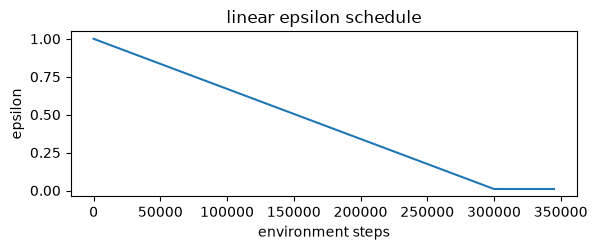

epsilon: 1.00 at step 0 -> 0.01 after 300,000 steps


In [8]:
# @title 7. Exploration schedule
eps_cfg = dict(spec["eps"])
if BUDGET is not None and BUDGET[0] == "steps":  # run_one scales the decay to the budget
    eps_cfg["eps_decay_steps"] = min(eps_cfg["eps_decay_steps"], BUDGET[1])
steps = np.linspace(0, eps_cfg["eps_decay_steps"] * 1.15, 200)
eps = [epsilon_at(int(s), **eps_cfg) for s in steps]
plt.figure(figsize=(6, 2.6))
plt.plot(steps, eps)
plt.xlabel("environment steps"); plt.ylabel("epsilon")
plt.title("linear epsilon schedule")
plt.tight_layout(); plt.show()
print(f"epsilon: {eps[0]:.2f} at step 0 -> {eps[-1]:.2f} after "
      f"{eps_cfg['eps_decay_steps']:,} steps")

## 2. The four agents

| Agent | Target `y` | Network |
|---|---|---|
| `hard` (reference) | `r + γ(1−d)·maxₐ′ Q(s′, a′; θ⁻)` | standard head |
| `double` | `r + γ(1−d)·Q(s′, argmaxₐ′ Q(s′, a′; θ); θ⁻)` | standard head |
| `dueling` | DQN target | dueling head |
| `dueling_double` | Double DQN target | dueling head |

**Bias measurement.** The greedy evaluation episodes give, for every visited state `s`, both the
value predicted by the network (the Q-value of the action it actually takes) and the empirical
discounted return `G_t = Σₖ γᵏ r_{t+k}` obtained from that same state. Overestimation is then

```
bias = mean over evaluation states of Q(s, a) − mean over the same states of G_t
```

A positive bias means the agent promises itself more than it actually gets — the pathology that
Double DQN was introduced to remove.

**Budget.** The reference budget of Part 0 is 10^6 environment steps per run. A calibration of the
exact training loop on this GPU (`scripts/calibrate.py`) measures about 154 environment steps per
second, i.e. 1 h 47 per run and **38 GPU-hours** for the 21 Pong runs. We therefore use the same
reduced budget of **300,000 steps for every variant and every seed**, as the
assignment allows, and say so wherever the Pong curves are read. The epsilon decay is scaled from
10^6 to 300,000 steps (`agent.eps`), so that epsilon still reaches its final value
at the end of training instead of stalling at 0.7; the calibration and the resulting table are in
the report, §6.

In [9]:
# @title 8. Train 4 variants x 3 seeds
RESULTS = run_matrix(ENV_NAME, VARIANTS, seeds=SEEDS, budget=BUDGET, out_dir="runs",
                     device=DEVICE, verbose=True, force=(RUN_MODE == "train"))

summary = pd.DataFrame([
    dict(variant=v, seed=r["seed"], episodes=int(r["n_episodes"]),
         env_steps=int(r["env_steps"]), updates=int(r["updates"]),
         train_score=float(np.mean(r["episode_returns"][-spec["metric_window"]:])),
         greedy=float(np.mean(r["eval_returns"])),
         minutes=float(r["wall_time"]) / 60)
    for v, runs in RESULTS.items() for r in runs])
display(summary.round(2))

[skip] pong/hard seed 0: runs/pong/hard_s0.npz already exists
[skip] pong/hard seed 1: runs/pong/hard_s1.npz already exists
[skip] pong/hard seed 2: runs/pong/hard_s2.npz already exists
[skip] pong/double seed 0: runs/pong/double_s0.npz already exists
[skip] pong/double seed 1: runs/pong/double_s1.npz already exists
[skip] pong/double seed 2: runs/pong/double_s2.npz already exists
[skip] pong/dueling seed 0: runs/pong/dueling_s0.npz already exists
[skip] pong/dueling seed 1: runs/pong/dueling_s1.npz already exists
[skip] pong/dueling seed 2: runs/pong/dueling_s2.npz already exists
[skip] pong/dueling_double seed 0: runs/pong/dueling_double_s0.npz already exists
[skip] pong/dueling_double seed 1: runs/pong/dueling_double_s1.npz already exists
[skip] pong/dueling_double seed 2: runs/pong/dueling_double_s2.npz already exists


,variant,seed,episodes,env_steps,updates,train_score,greedy,minutes
0,hard,0,204,300000,290001,-11.05,-11.15,30.39
1,hard,1,343,300000,290001,-20.40,-21.00,30.44
2,hard,2,191,300000,290001,-9.30,-4.10,29.28
3,double,0,212,300000,290001,-13.60,-7.90,30.58
4,double,1,204,300000,290001,-9.80,-5.55,30.28
5,double,2,335,300000,290001,-20.40,-21.00,31.15
6,dueling,0,349,300000,290001,-20.10,-21.00,35.83
7,dueling,1,196,300000,290001,-5.50,-0.30,34.76
8,dueling,2,198,300000,290001,-4.30,1.05,34.85
9,dueling_double,0,349,300000,290001,-20.90,-21.00,37.77


## 3. Learning curves

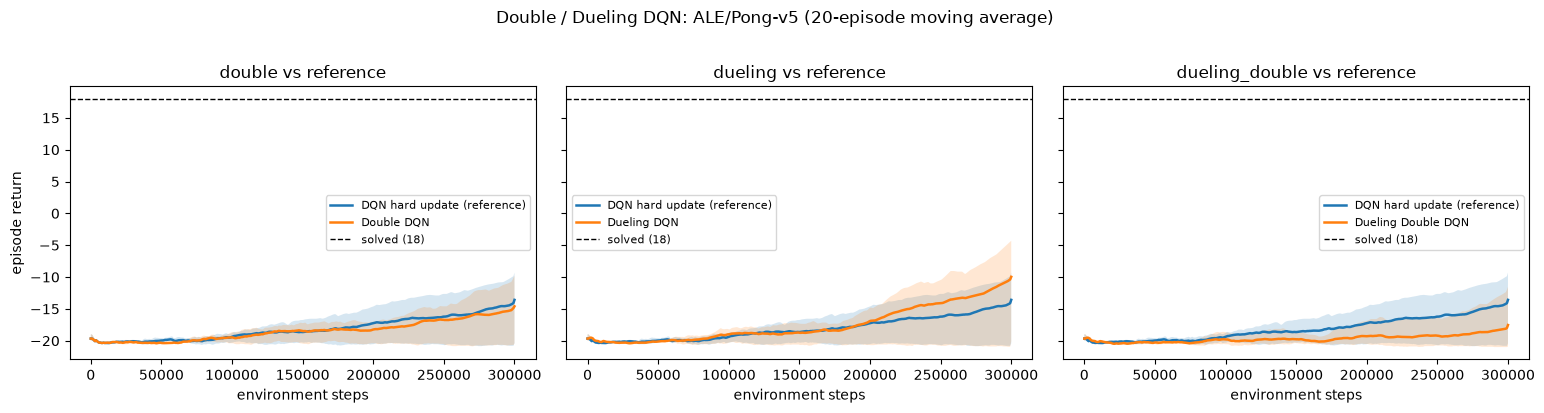

In [10]:
# @title 9. Learning curves — mean over 3 seeds, band = min–max
pairs = PAIRS
fig, axes = plt.subplots(1, len(pairs), figsize=(5.2 * len(pairs), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, (a, b) in zip(axes, pairs):
    runs = {}
    for name in (a, b):
        if name in RESULTS:
            runs[variant_label(name)] = RESULTS[name]
    plot_curves(ax, runs, window=WINDOW, x_key=X_KEY,
                threshold=spec["target_score"],
                title=f"{b} vs reference" if b != "hard" else "reference")
axes[0].set_ylabel("episode return")
for extra in axes[1:]:
    extra.set_ylabel("")
fig.suptitle("Double / Dueling DQN: " + spec["label"] + " (20-episode moving average)", y=1.02)
plt.tight_layout(); plt.show()

## 4. Predicted Q-values during training

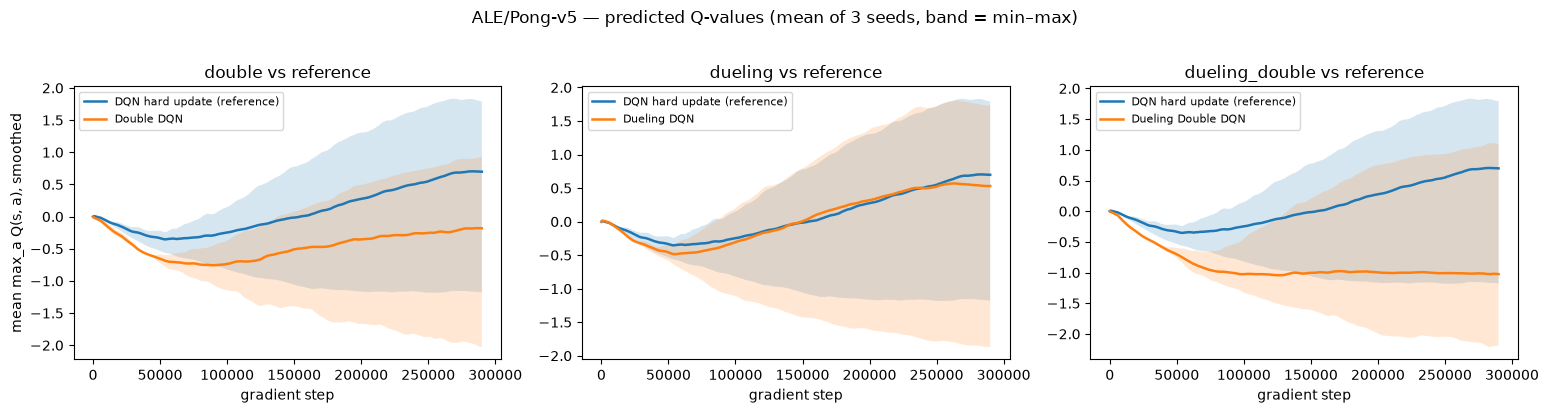

In [11]:
# @title 10. Predicted Q-values during training
fig, axes = plt.subplots(1, len(pairs), figsize=(5.2 * len(pairs), 4))
axes = np.atleast_1d(axes)
for ax, (a, b) in zip(axes, pairs):
    runs = {}
    for name in (a, b):
        if name in RESULTS:
            runs[variant_label(name)] = RESULTS[name]
    plot_q_curves(ax, runs, title=f"{b} vs reference")
    if spec["q_reference"] is not None:
        ax.axhline(spec["q_reference"], ls="--", c="k", lw=1,
                   label="1/(1-gamma)")
axes[0].set_ylabel("mean max_a Q(s, a), smoothed")
for extra in axes[1:]:
    extra.set_ylabel("")
fig.suptitle(spec["label"] + " — predicted Q-values (mean of 3 seeds, band = min–max)", y=1.02)
plt.tight_layout(); plt.show()

## 5. Overestimation bias

For every state visited by the greedy policy we compare the value predicted by the network with
the discounted return actually obtained from that state (20 evaluation episodes, seeds
100 000 + i).

In [12]:
# @title 11. Bias: predicted Q(s, a) minus the empirical discounted return
rows = []
for variant, runs in RESULTS.items():
    for run in runs:
        rows.append(dict(variant=variant, seed=run["seed"],
                         q_pred=float(np.mean(run["eval_q_pred"])),
                         mc_return=float(np.mean(run["eval_mc_return"])),
                         bias=float(run["bias"]),
                         truncated=float(np.mean(np.asarray(run["eval_lengths"])
                                                 >= spec["max_episode_steps"]))
                         if spec["max_episode_steps"] else np.nan))
bias = pd.DataFrame(rows)
display(bias.round(2))
aggregated = bias.groupby("variant").agg(q_pred=("q_pred", "mean"),
                                         mc_return=("mc_return", "mean"),
                                         bias=("bias", "mean"),
                                         bias_min=("bias", "min"),
                                         bias_max=("bias", "max"),
                                         truncated=("truncated", "mean"))
display(aggregated.round(2))

,variant,seed,q_pred,mc_return,bias,truncated
0,hard,0,1.52,-0.34,1.86,NaN
1,hard,1,-1.18,-2.52,1.34,NaN
2,hard,2,1.76,-0.11,1.88,NaN
3,double,0,0.58,-0.27,0.85,NaN
4,double,1,0.94,-0.17,1.10,NaN
5,double,2,-1.99,-2.52,0.53,NaN
6,dueling,0,-1.87,-2.52,0.65,NaN
7,dueling,1,1.55,-0.01,1.56,NaN
8,dueling,2,1.71,0.03,1.68,NaN
9,dueling_double,0,-1.99,-2.52,0.53,NaN


,q_pred,mc_return,bias,bias_min,bias_max,truncated
variant,,,,,,
double,-0.16,-0.99,0.83,0.53,1.10,NaN
dueling,0.46,-0.83,1.30,0.65,1.68,NaN
dueling_double,-1.05,-1.73,0.68,0.29,1.21,NaN
hard,0.70,-0.99,1.69,1.34,1.88,NaN


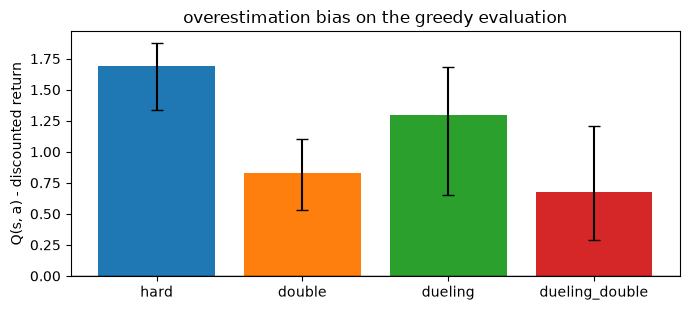

In [13]:
# @title 12. Bias per agent (bar = mean over seeds, whiskers = min–max)
order = [v for v in VARIANTS if v in aggregated.index]
fig, ax = plt.subplots(figsize=(7, 3.2))
means = aggregated.loc[order, "bias"]
lower = means - aggregated.loc[order, "bias_min"]
upper = aggregated.loc[order, "bias_max"] - means
ax.bar(range(len(order)), means, yerr=[lower, upper], capsize=4,
       color=[f"C{VARIANTS.index(v)}" for v in order])
ax.axhline(0, c="k", lw=1)
ax.set_xticks(range(len(order)), order)
ax.set(ylabel="Q(s, a) - discounted return", title="overestimation bias on the greedy evaluation")
plt.tight_layout(); plt.show()

## 6. Greedy evaluation

Every saved network plays 20 new episodes with ε = 0 and seeds 100 000 + i, which were never
used during training.

In [14]:
# @title 11. Summary table (training score, greedy score, band across seeds)
table = summary_table(RESULTS, ENV_NAME)
display(table.round(2))
per_seed = pd.DataFrame([
    dict(variant=v, seed=r["seed"], greedy=float(np.mean(r["eval_returns"])),
         std=float(np.std(r["eval_returns"])))
    for v, runs in RESULTS.items() for r in runs])
display(per_seed.pivot(index="variant", columns="seed", values="greedy").round(1))

,train_score,greedy_mean,greedy_min,greedy_max,greedy_std,solved,eval_length,bias,env_steps,minutes,seeds
variant,,,,,,,,,,,
hard,-13.58,-12.08,-21.0,-4.10,6.93,False,2493.33,1.69,300000.0,30.04,3
double,-14.60,-11.48,-21.0,-5.55,6.80,False,2339.95,0.83,300000.0,30.67,3
dueling,-9.97,-6.75,-21.0,1.05,10.09,False,3525.32,1.30,300000.0,35.15,3
dueling_double,-17.53,-15.60,-21.0,-4.80,7.64,False,1632.47,0.68,300000.0,37.81,3


seed,0,1,2
variant,,,
double,-7.9,-5.6,-21.0
dueling,-21.0,-0.3,1.0
dueling_double,-21.0,-21.0,-4.8
hard,-11.2,-21.0,-4.1


In [15]:
# @title 12. Is a difference larger than the min–max band across seeds?
rows = []
for a, b in PAIRS:
    if a in RESULTS and b in RESULTS:
        c = compare(RESULTS[a], RESULTS[b])
        rows.append(dict(comparison=f"{a} vs {b}", mean_a=c["mean_a"], mean_b=c["mean_b"],
                         difference=c["difference"], min_max_band=c["band"],
                         significant=c["significant"]))
display(pd.DataFrame(rows).round(2))

,comparison,mean_a,mean_b,difference,min_max_band,significant
0,hard vs double,-12.08,-11.48,-0.60,16.90,False
1,hard vs dueling,-12.08,-6.75,-5.33,22.05,False
2,hard vs dueling_double,-12.08,-15.60,3.52,16.90,False


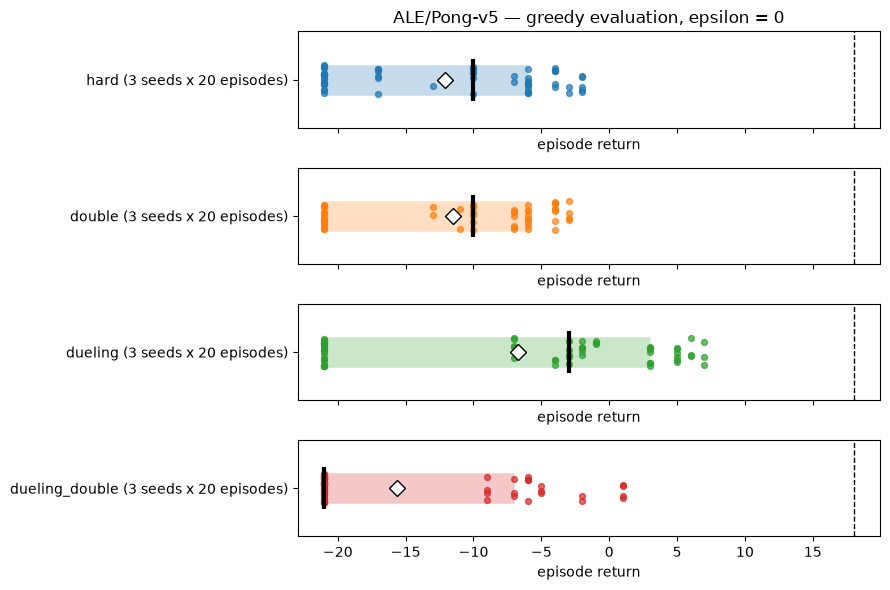

In [16]:
# @title 13. Strip plot of the 20 greedy evaluation episodes
fig, axes = plt.subplots(len(VARIANTS), 1, figsize=(9, 1.5 * len(VARIANTS)), sharex=True)
axes = np.atleast_1d(axes)
for ax, variant in zip(axes, VARIANTS):
    returns = np.concatenate([r["eval_returns"] for r in RESULTS[variant]])
    strip_plot(ax, returns, f"{variant} ({len(RESULTS[variant])} seeds x 20 episodes)",
               spec["target_score"], color=f"C{VARIANTS.index(variant)}")
axes[0].set_title(f"{spec['label']} — greedy evaluation, epsilon = 0")
plt.tight_layout(); plt.show()

## 7. Saved networks

The deliverable requires the network of the best seed of every agent.

In [17]:
# @title 14. Save the best seed of each variant
saved = []
for variant, runs in RESULTS.items():
    best = max(runs, key=lambda r: float(np.mean(r["eval_returns"])))
    destination = (f"deliverables/EX2_{ENV_NAME}_{variant}_seed{best['seed']}.pth")
    shutil.copy(best["pth_path"], destination)
    saved.append(dict(variant=variant, seed=best["seed"],
                      greedy=float(np.mean(best["eval_returns"])),
                      train_score=float(np.mean(best["episode_returns"][-spec["metric_window"]:])),
                      file=destination))
display(pd.DataFrame(saved).round(2))

,variant,seed,greedy,train_score,file
0,hard,2,-4.10,-9.30,deliverables/EX2_pong_hard_seed2.pth
1,double,1,-5.55,-9.80,deliverables/EX2_pong_double_seed1.pth
2,dueling,2,1.05,-4.30,deliverables/EX2_pong_dueling_seed2.pth
3,dueling_double,2,-4.80,-11.55,deliverables/EX2_pong_dueling_double_seed2.pth


## 8. Conclusion — ALE/Pong-v5

(Filled in from the numbers above; the text below is generated when the cell runs.)

In [18]:
# @title 15. Data-driven conclusion
rows = []
for variant, runs in RESULTS.items():
    greedy = [float(np.mean(r["eval_returns"])) for r in runs]
    train = [float(np.mean(r["episode_returns"][-spec["metric_window"]:])) for r in runs]
    rows.append((variant, np.mean(train), np.mean(greedy), np.min(greedy), np.max(greedy)))
frame = pd.DataFrame(rows, columns=["variant", "train", "greedy", "min", "max"]).set_index("variant")
reference = frame.loc["hard"] if "hard" in frame.index else frame.iloc[0]
print(f"{spec['label']} — training score / greedy score (mean of 3 seeds)")
for variant, row in frame.iterrows():
    delta = row.greedy - reference.greedy
    print(f"  {variant:15s} {row.train:7.1f} / {row.greedy:7.1f}  "
          f"({'+' if delta >= 0 else ''}{delta:6.1f} vs reference, band "
          f"{row['max'] - row['min']:.1f})")
best = frame.greedy.idxmax()
print(f"\nbest greedy policy: {best} ({frame.loc[best, 'greedy']:.1f}); "
      f"target {spec['target_score']}")

ALE/Pong-v5 — training score / greedy score (mean of 3 seeds)
  hard              -13.6 /   -12.1  (+   0.0 vs reference, band 16.9)
  double            -14.6 /   -11.5  (+   0.6 vs reference, band 15.4)
  dueling           -10.0 /    -6.8  (+   5.3 vs reference, band 22.1)
  dueling_double    -17.5 /   -15.6  (  -3.5 vs reference, band 16.2)

best greedy policy: dueling (-6.8); target 18.0
